# Amazon Review Sentiment: Compare 1:3, 1:5 and 1:8 Class Weights

## Objective
Compare TF-IDF + Logistic Regression for sentiment classification using three **positive:negative class-weight ratios**: **1:3, 1:5 and 1:8**. This means negative examples receive weights 3, 5 or 8 while positive examples receive weight 1.

The dataset is not rebalanced by adding/removing rows; class weights change the penalty for errors during model fitting.

## 1. Import libraries

In [1]:
import html
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, balanced_accuracy_score, classification_report,
    confusion_matrix, roc_auc_score
)

RANDOM_STATE = 42
DATA_PATH = "amazon_reviews.csv"
sns.set_theme(style="whitegrid")

## 2. Load data and handle missing values
We exclude rows with missing/invalid target labels. Missing review text is filled with an empty string, then empty reviews are excluded because they provide no textual sentiment evidence.

In [2]:
df = pd.read_csv(DATA_PATH)
required = {"verified_reviews", "feedback"}
if not required.issubset(df.columns):
    raise ValueError(f"Dataset must contain columns: {required}")

work = df[["verified_reviews", "feedback"]].copy()
n_original = len(work)
n_missing_target = int(work["feedback"].isna().sum())

work["feedback"] = pd.to_numeric(work["feedback"], errors="coerce")
work = work.dropna(subset=["feedback"])
work = work[work["feedback"].isin([0, 1])].copy()
work["feedback"] = work["feedback"].astype(int)
work["verified_reviews"] = work["verified_reviews"].fillna("").astype(str).map(html.unescape).str.strip()
n_empty_text = int(work["verified_reviews"].eq("").sum())
work = work.loc[work["verified_reviews"].ne("")].copy()

print("Original rows:", n_original)
print("Missing target rows initially:", n_missing_target)
print("Empty/missing review texts excluded:", n_empty_text)
print("Rows used:", len(work))
display(work.head())

Original rows: 3150
Missing target rows initially: 0
Empty/missing review texts excluded: 80
Rows used: 3070


,verified_reviews,feedback
0,Love my Echo!,1
1,Loved it!,1
2,"Sometimes while playing a game, you can answer...",1
3,I have had a lot of fun with this thing. My 4 ...,1
4,Music,1


**Interpretation:** Missing target labels cannot be imputed safely for supervised classification, so they are removed. Empty reviews are also excluded after missing text is filled, because an empty string contains no sentiment signal.

## 3. Check the actual imbalance
The class counts below verify the ratio in the data after cleaning.

In [3]:
counts = work["feedback"].value_counts().reindex([0, 1], fill_value=0)
n_negative, n_positive = int(counts[0]), int(counts[1])
print(f"Negative reviews (feedback=0): {n_negative}")
print(f"Positive reviews (feedback=1): {n_positive}")
print(f"Positive:negative count ratio = 1:{n_positive/n_negative:.2f}")
print(f"Negative share = {n_negative/len(work):.2%}")
print(f"Positive share = {n_positive/len(work):.2%}")

display(pd.DataFrame({
    "count": [n_negative, n_positive],
    "percentage": [100*n_negative/len(work), 100*n_positive/len(work)]
}, index=["Negative (0)", "Positive (1)"]).round(2))

Negative reviews (feedback=0): 237
Positive reviews (feedback=1): 2833
Positive:negative count ratio = 1:11.95
Negative share = 7.72%
Positive share = 92.28%


,count,percentage
Negative (0),237,7.72
Positive (1),2833,92.28


**Interpretation:** The ratio printed by this cell is the observed class ratio, which is distinct from the class-weight ratio. Class weighting does not change the dataset counts.

## 4. Create one fixed train/test split
All weight settings use the same stratified split so that the comparison is fair.

In [4]:
X = work["verified_reviews"]
y = work["feedback"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y
)
print("Training rows:", len(X_train))
print("Test rows:", len(X_test))

Training rows: 2456
Test rows: 614


**Interpretation:** The test set is not used to fit the models. Keeping the split fixed ensures differences in results are due to the class weights rather than different test reviews.

## 5. Fit and compare the three models
Weight mapping: `{0: 3, 1: 1}`, `{0: 5, 1: 1}`, and `{0: 8, 1: 1}`. Here class 0 is negative and class 1 is positive.

In [5]:
weight_settings = {
    "1:3 (positive:negative)": {0: 3, 1: 1},
    "1:5 (positive:negative)": {0: 5, 1: 1},
    "1:8 (positive:negative)": {0: 8, 1: 1},
}

models = {}
result_rows = []
confusion_matrices = {}

for setting_name, weights in weight_settings.items():
    model = Pipeline([
        ("tfidf", TfidfVectorizer(
            lowercase=True, stop_words="english", ngram_range=(1, 2),
            min_df=2, max_features=50000, sublinear_tf=True
        )),
        ("logreg", LogisticRegression(
            max_iter=2000, class_weight=weights, random_state=RANDOM_STATE
        ))
    ])
    model.fit(X_train, y_train)
    pred = model.predict(X_test)
    prob_positive = model.predict_proba(X_test)[:, 1]

    report = classification_report(
        y_test, pred, labels=[0, 1],
        target_names=["Negative", "Positive"],
        output_dict=True, zero_division=0
    )
    cm = confusion_matrix(y_test, pred, labels=[0, 1])
    models[setting_name] = model
    confusion_matrices[setting_name] = cm

    result_rows.append({
        "Weight ratio (positive:negative)": setting_name,
        "Accuracy": accuracy_score(y_test, pred),
        "Balanced accuracy": balanced_accuracy_score(y_test, pred),
        "ROC-AUC": roc_auc_score(y_test, prob_positive),
        "Negative precision": report["Negative"]["precision"],
        "Negative recall": report["Negative"]["recall"],
        "Negative F1": report["Negative"]["f1-score"],
        "Positive precision": report["Positive"]["precision"],
        "Positive recall": report["Positive"]["recall"],
        "Positive F1": report["Positive"]["f1-score"],
        "Macro F1": report["macro avg"]["f1-score"],
        "TN": cm[0, 0],
        "FP": cm[0, 1],
        "FN": cm[1, 0],
        "TP": cm[1, 1],
    })

results = pd.DataFrame(result_rows).set_index("Weight ratio (positive:negative)")
display(results.round(4))

,Accuracy,Balanced accuracy,ROC-AUC,Negative precision,Negative recall,Negative F1,Positive precision,Positive recall,Positive F1,Macro F1,TN,FP,FN,TP
Weight ratio (positive:negative),,,,,,,,,,,,,,
1:3 (positive:negative),0.9446,0.6481,0.9680,0.9333,0.2979,0.4516,0.9449,0.9982,0.9708,0.7112,14,33,1,566
1:5 (positive:negative),0.9495,0.7483,0.9690,0.7500,0.5106,0.6076,0.9605,0.9859,0.9730,0.7903,24,23,8,559
1:8 (positive:negative),0.9544,0.8192,0.9697,0.7209,0.6596,0.6889,0.9720,0.9788,0.9754,0.8321,31,16,12,555


## 6. Interpret the comparison

- **Negative recall** answers: of all genuinely negative reviews, what fraction did the model identify as negative?
- **Negative precision** answers: of all reviews predicted as negative, what fraction were actually negative?
- **Macro F1** averages class-specific F1 equally, so the majority positive class does not dominate it.
- **Balanced accuracy** averages the recall for negative and positive classes.
- **ROC-AUC** evaluates ranking across thresholds, not just the default 0.5 decision threshold.

Increasing the negative class weight often makes the model more willing to predict negative, but this is not guaranteed to improve every metric. Choose a setting based on the business cost of missed negative reviews versus false alarms.

## 7. Confusion matrices for each setting
Rows are actual labels and columns are predicted labels. Label order is Negative (0), Positive (1).

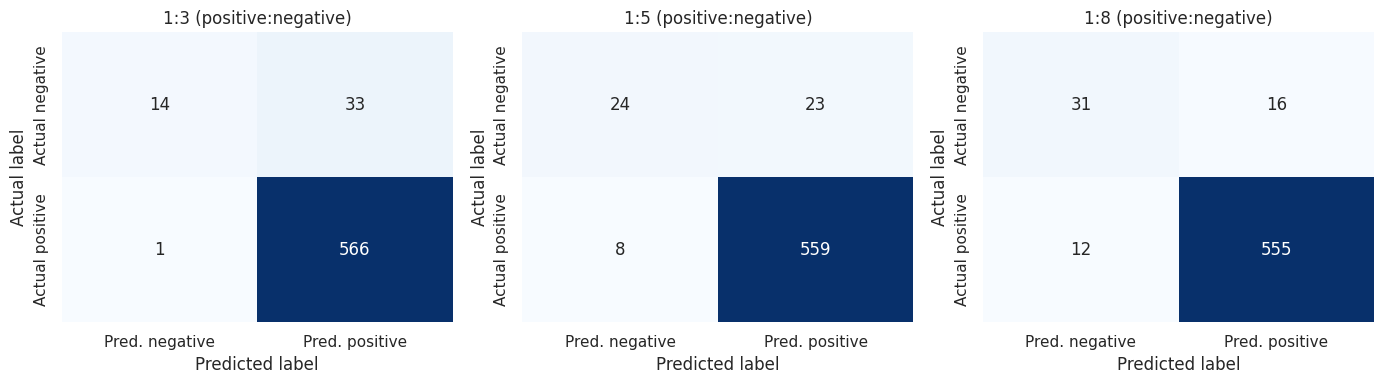

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, (setting_name, cm) in zip(axes, confusion_matrices.items()):
    sns.heatmap(
        cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax,
        xticklabels=["Pred. negative", "Pred. positive"],
        yticklabels=["Actual negative", "Actual positive"]
    )
    ax.set_title(setting_name)
    ax.set_xlabel("Predicted label")
    ax.set_ylabel("Actual label")
plt.tight_layout()
plt.show()

**Confusion-matrix note:** With label order `[0, 1]`, the top-left cell is true negatives, top-right is actual negative predicted positive (negative reviews missed), bottom-left is actual positive predicted negative, and bottom-right is true positives.

## 8. Optional: inspect full classification reports

In [7]:
for setting_name, model in models.items():
    pred = model.predict(X_test)
    print("\\n" + "=" * 72)
    print(setting_name)
    print(classification_report(
        y_test, pred, labels=[0, 1],
        target_names=["Negative", "Positive"], zero_division=0
    ))

\n========================================================================
1:3 (positive:negative)
              precision    recall  f1-score   support

    Negative       0.93      0.30      0.45        47
    Positive       0.94      1.00      0.97       567

    accuracy                           0.94       614
   macro avg       0.94      0.65      0.71       614
weighted avg       0.94      0.94      0.93       614

\n========================================================================
1:5 (positive:negative)
              precision    recall  f1-score   support

    Negative       0.75      0.51      0.61        47
    Positive       0.96      0.99      0.97       567

    accuracy                           0.95       614
   macro avg       0.86      0.75      0.79       614
weighted avg       0.94      0.95      0.95       614

\n========================================================================
1:8 (positive:negative)
              precision    recall  f1-score   sup

## 9. Conclusion and next steps

Do not select a weight solely because it is numerically larger. Compare negative recall, negative precision, macro F1 and balanced accuracy together. If missing negative reviews is particularly costly, consider prioritizing recall, while keeping an eye on the number of positive reviews incorrectly flagged as negative.

For a stronger estimate, repeat this comparison using stratified cross-validation on the training data and choose the final weight there; keep the test set for final evaluation. The current results are from one fixed hold-out split.